# **1. Import libraries**

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image

# Preprocessing
from sklearn.model_selection import train_test_split as tts

# Torch
import torch
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
from torchinfo import summary
from torchvision.models import vit_b_16, ViT_B_16_Weights

# Metrics
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import confusion_matrix

# os
import os

# Path
from pathlib import Path

# random
import random

# OrderedDict
from collections import OrderedDict

# tqdm
from tqdm.auto import tqdm

# warnings
import warnings
warnings.filterwarnings("ignore")

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.3
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


# **2. Load data**

In [2]:
IMAGE_PATH = Path("/kaggle/input/pharmaceutical-and-biomedical-waste/Pharmaceutical and Biomedical Waste (PBW)")

IMAGE_PATH_LIST = list(IMAGE_PATH.glob("*/*/*.jpg"))
print(f'Total Images = {len(IMAGE_PATH_LIST)}')

Total Images = 6156


In [3]:
CLASSES = os.listdir(IMAGE_PATH)
CLASSES = sorted(CLASSES)

print(f"Total Classes = {len(CLASSES)}:\n")
for label in CLASSES:
    total_images_class = list(Path(os.path.join(IMAGE_PATH,label)).glob("*/*.jpg"))
    print(f'* {label}: {len(total_images_class)} images')

Total Classes = 12:

* (BT) Body Tissue or Organ: 474 images
* (GE) Glass equipment-packaging 551: 551 images
* (ME) Metal equipment -packaging: 426 images
* (OW) Organic wastes: 583 images
* (PE) Plastic equipment-packaging: 558 images
* (PP) Paper equipment-packaging: 457 images
* (SN) Syringe needles: 513 images
* Gauze: 510 images
* Gloves: 543 images
* Mask: 529 images
* Syringe: 473 images
* Tweezers: 539 images


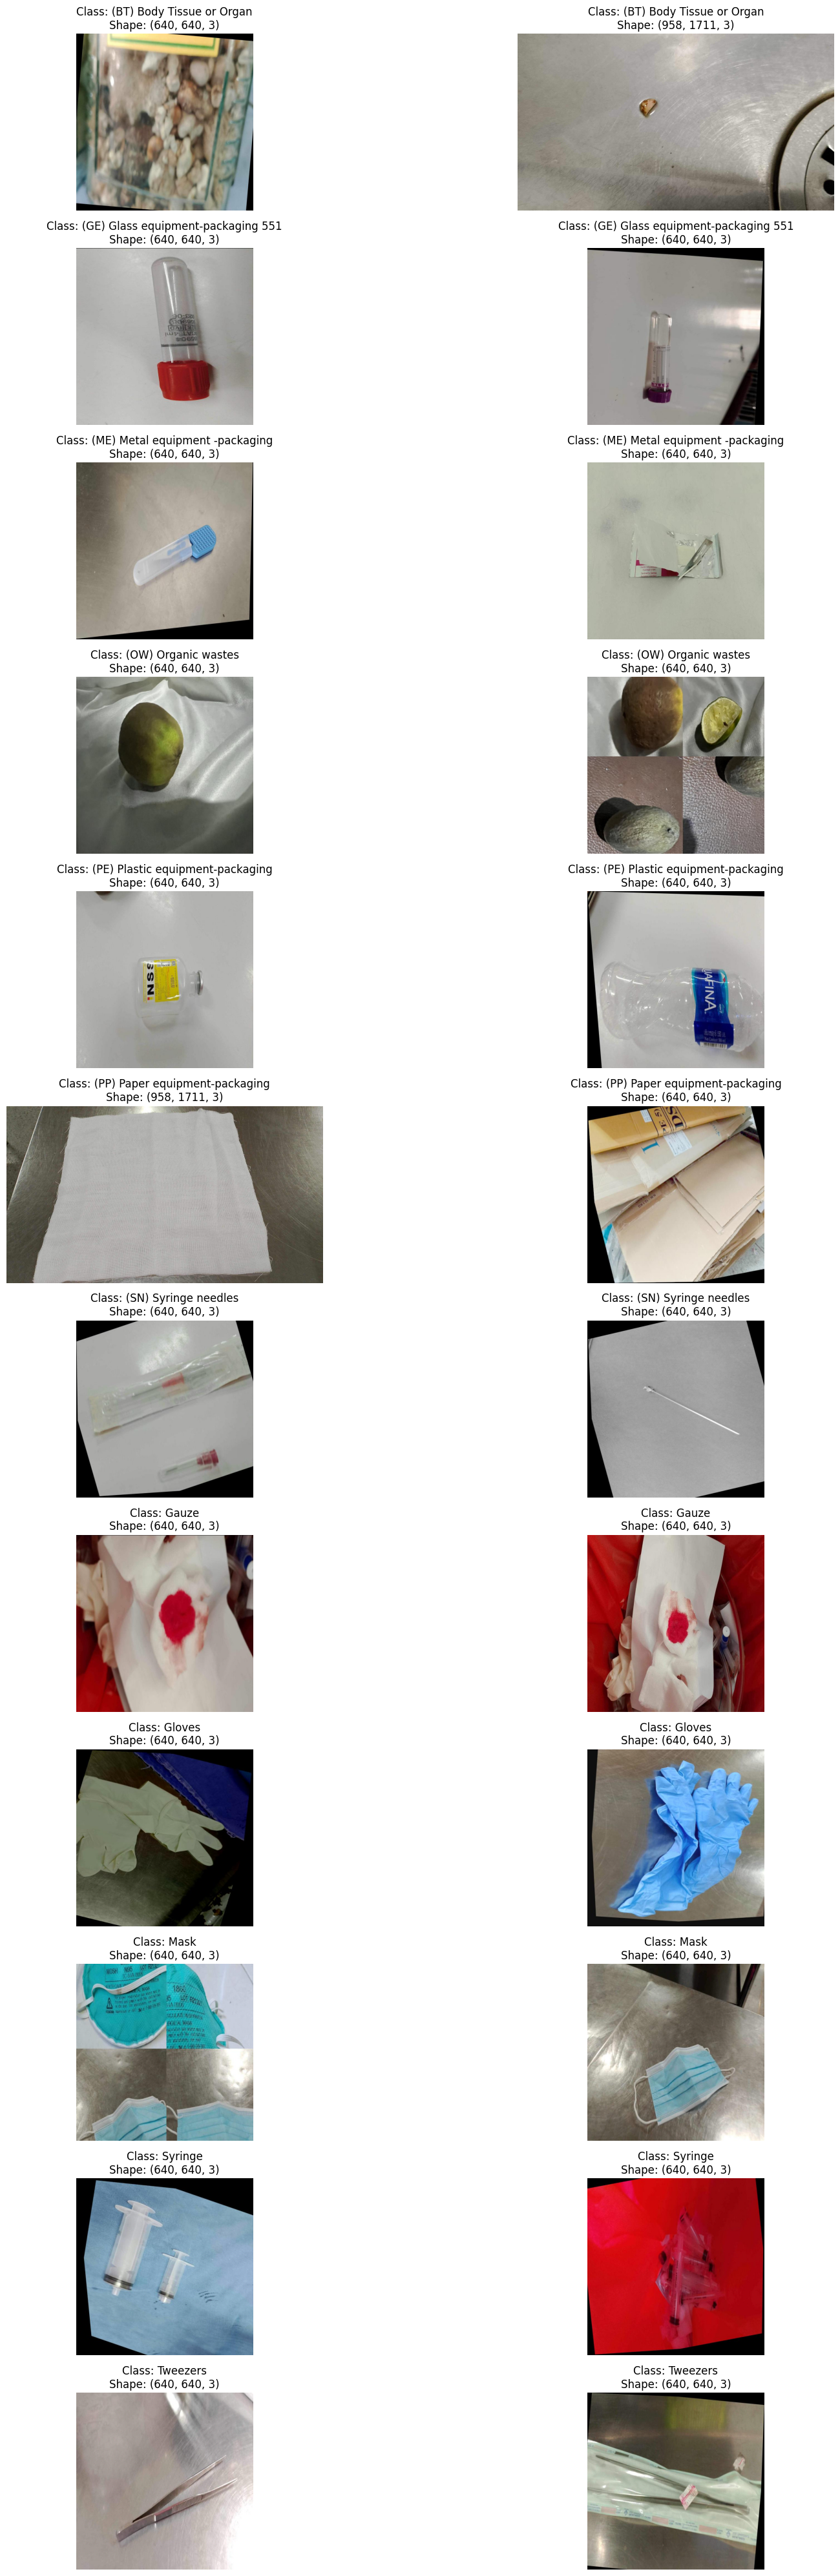

In [4]:
NUM_IMAGES = 2

fig,ax = plt.subplots(nrows = len(CLASSES), ncols = NUM_IMAGES, figsize = (20,40))

p = 0

for label in CLASSES:
    total_images_class = list(Path(os.path.join(IMAGE_PATH,label)).glob("*/*.jpg"))
    total_selected = random.choices(total_images_class, k = NUM_IMAGES)
    
    for i,img_path in enumerate(total_selected):
        img_bgr = cv2.imread(str(img_path))
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        ax[p,i].imshow(img_rgb)
        ax[p,i].axis('off')
        ax[p,i].set_title(f'Class: {label}\nShape: {img_rgb.shape}')
        
    p += 1
    
fig.tight_layout()
fig.show()
    

# **3. Preprocessing**

**Create lists to store image paths and their respective labels.**

In [5]:
images_path_train = list()
labels_train = list()

images_path_test = list()
labels_test = list()

for i in IMAGE_PATH_LIST:
    if i.parent.stem == 'Train images':
        images_path_train.append(i)
        labels_train.append(i.parent.parent.stem)
        
    else:
        images_path_test.append(i)
        labels_test.append(i.parent.parent.stem)

**Now we convert it into dataframes.**

In [6]:
data_train = pd.DataFrame({'Image':images_path_train, 'Label':labels_train})
data_train.head()

,Image,Label
0,/kaggle/input/pharmaceutical-and-biomedical-wa...,(BT) Body Tissue or Organ
1,/kaggle/input/pharmaceutical-and-biomedical-wa...,(BT) Body Tissue or Organ
2,/kaggle/input/pharmaceutical-and-biomedical-wa...,(BT) Body Tissue or Organ
3,/kaggle/input/pharmaceutical-and-biomedical-wa...,(BT) Body Tissue or Organ
4,/kaggle/input/pharmaceutical-and-biomedical-wa...,(BT) Body Tissue or Organ


In [7]:
data_testing = pd.DataFrame({'Image':images_path_test, 'Label':labels_test})
data_testing.head()

,Image,Label
0,/kaggle/input/pharmaceutical-and-biomedical-wa...,(BT) Body Tissue or Organ
1,/kaggle/input/pharmaceutical-and-biomedical-wa...,(BT) Body Tissue or Organ
2,/kaggle/input/pharmaceutical-and-biomedical-wa...,(BT) Body Tissue or Organ
3,/kaggle/input/pharmaceutical-and-biomedical-wa...,(BT) Body Tissue or Organ
4,/kaggle/input/pharmaceutical-and-biomedical-wa...,(BT) Body Tissue or Organ


**Now we divide into training, validation and testing**.

In [8]:
SEED = 42

data_training, data_validation = tts(data_train, test_size = 0.3, random_state = SEED, 
                                     shuffle = data_train['Label'])

print(data_training.shape), print(data_validation.shape)

(3432, 2)
(1471, 2)


(None, None)

In [9]:
# We created a dictionary to map the image tags.
label2id = dict(zip(CLASSES, range(len(CLASSES))))
label2id

{'(BT) Body Tissue or Organ': 0,
 '(GE) Glass equipment-packaging 551': 1,
 '(ME) Metal equipment -packaging': 2,
 '(OW) Organic wastes': 3,
 '(PE) Plastic equipment-packaging': 4,
 '(PP) Paper equipment-packaging': 5,
 '(SN) Syringe needles': 6,
 'Gauze': 7,
 'Gloves': 8,
 'Mask': 9,
 'Syringe': 10,
 'Tweezers': 11}

We create **Dataset's** and **DataLoader's**

- **Dataset**

In [10]:
class CustomImageDataset(Dataset):
    def __init__(self, data:pd.DataFrame, label_map:dict, transforms):
        self.data = data
        self.label_map = label_map
        self.transforms = transforms
        
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        data_new = self.data.copy()
        data_new['Label'] = data_new['Label'].map(self.label_map)
        
        image_path = data_new.iloc[idx, 0]
        image = Image.open(image_path).convert("RGB")
        image = self.transforms(image)
        
        label = data_new.iloc[idx, 1]
        
        return image,label

**We define the weights and transformations that we are going to apply to our images.**

In [11]:
weights = ViT_B_16_Weights.DEFAULT
image_transforms = weights.transforms()
image_transforms

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

In [12]:
train_dataset = CustomImageDataset(data_training, label2id, image_transforms)

val_dataset = CustomImageDataset(data_validation, label2id, image_transforms)

- **DataLoader**

In [29]:
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

train_dataloader = DataLoader(dataset = train_dataset, batch_size = BATCH_SIZE, 
                              shuffle = True, num_workers = NUM_WORKERS)

val_dataloader = DataLoader(dataset = val_dataset, batch_size = BATCH_SIZE, 
                            shuffle = True, num_workers = NUM_WORKERS)

In [14]:
# We visualize the dimensions of a batch.
batch_images, batch_labels = next(iter(train_dataloader))

batch_images.shape, batch_labels.shape

(torch.Size([32, 3, 224, 224]), torch.Size([32]))

# **4. Model**

In [15]:
# GPU

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE

'cuda'

In [16]:
# Define model
model = vit_b_16(weights = weights)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth
100%|██████████| 330M/330M [00:01<00:00, 247MB/s]  


In [17]:
# We visualize the architecture of our model.
summary(model = model, input_size = [32, 3, 224, 224], col_width = 15, 
        col_names = ['input_size', 'output_size', 'num_params', 'trainable'], 
        row_settings = ['var_names'])

Layer (type (var_name))                                      Input Shape     Output Shape    Param #         Trainable
VisionTransformer (VisionTransformer)                        [32, 3, 224, 224] [32, 1000]      768             True
├─Conv2d (conv_proj)                                         [32, 3, 224, 224] [32, 768, 14, 14] 590,592         True
├─Encoder (encoder)                                          [32, 197, 768]  [32, 197, 768]  151,296         True
│    └─Dropout (dropout)                                     [32, 197, 768]  [32, 197, 768]  --              --
│    └─Sequential (layers)                                   [32, 197, 768]  [32, 197, 768]  --              True
│    │    └─EncoderBlock (encoder_layer_0)                   [32, 197, 768]  [32, 197, 768]  7,087,872       True
│    │    └─EncoderBlock (encoder_layer_1)                   [32, 197, 768]  [32, 197, 768]  7,087,872       True
│    │    └─EncoderBlock (encoder_layer_2)                   [32, 197, 768]  [3

**We freeze the extractor layers.**

In [18]:
for param in model.conv_proj.parameters():
    param.requires_grad = False
    
for param in model.encoder.parameters():
    param.requires_grad = False

In [19]:
# We see if the extractor layers freeze.
summary(model = model, input_size = [32, 3, 224, 224], col_width = 15, 
        col_names = ['input_size', 'output_size', 'num_params', 'trainable'], 
        row_settings = ['var_names'])

Layer (type (var_name))                                      Input Shape     Output Shape    Param #         Trainable
VisionTransformer (VisionTransformer)                        [32, 3, 224, 224] [32, 1000]      768             Partial
├─Conv2d (conv_proj)                                         [32, 3, 224, 224] [32, 768, 14, 14] (590,592)       False
├─Encoder (encoder)                                          [32, 197, 768]  [32, 197, 768]  151,296         False
│    └─Dropout (dropout)                                     [32, 197, 768]  [32, 197, 768]  --              --
│    └─Sequential (layers)                                   [32, 197, 768]  [32, 197, 768]  --              False
│    │    └─EncoderBlock (encoder_layer_0)                   [32, 197, 768]  [32, 197, 768]  (7,087,872)     False
│    │    └─EncoderBlock (encoder_layer_1)                   [32, 197, 768]  [32, 197, 768]  (7,087,872)     False
│    │    └─EncoderBlock (encoder_layer_2)                   [32, 197, 

In [20]:
# We modify the output layer.
output_shape = len(CLASSES)

model.heads = nn.Sequential(OrderedDict([('head', nn.Linear(in_features = 768, out_features = output_shape))]))

In [21]:
# We view one last time to check if they were modified correctly.
summary(model = model, input_size = [32, 3, 224, 224], col_width = 15, 
        col_names = ['input_size', 'output_size', 'num_params', 'trainable'], 
        row_settings = ['var_names'])

Layer (type (var_name))                                      Input Shape     Output Shape    Param #         Trainable
VisionTransformer (VisionTransformer)                        [32, 3, 224, 224] [32, 12]        768             Partial
├─Conv2d (conv_proj)                                         [32, 3, 224, 224] [32, 768, 14, 14] (590,592)       False
├─Encoder (encoder)                                          [32, 197, 768]  [32, 197, 768]  151,296         False
│    └─Dropout (dropout)                                     [32, 197, 768]  [32, 197, 768]  --              --
│    └─Sequential (layers)                                   [32, 197, 768]  [32, 197, 768]  --              False
│    │    └─EncoderBlock (encoder_layer_0)                   [32, 197, 768]  [32, 197, 768]  (7,087,872)     False
│    │    └─EncoderBlock (encoder_layer_1)                   [32, 197, 768]  [32, 197, 768]  (7,087,872)     False
│    │    └─EncoderBlock (encoder_layer_2)                   [32, 197, 

We define the **loss function** and the **optimizer**.

In [22]:
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 0.01, weight_decay = 0.0001)

We define some functions for training:
- **train_step**
- **val_step**
- **EarlyStopping**
- **predictions**

In [23]:
class EarlyStopping:
    def __init__(self, patience:int = 10, delta:float = 0.0001, path:str = "best_model.pth"):
        self.patience = patience
        self.delta = delta
        self.path = path
        self.best_score = None
        self.counter = 0
        self.early_stop = False
        
    def __call__(self, val_loss, model):
        if self.best_score is None:
            self.best_score = val_loss
            self.save_checkpoint(model)
            
        elif val_loss > self.best_score + self.delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
                
        else:
            self.best_score = val_loss
            self.save_checkpoint(model)
            self.counter = 0
            
    def save_checkpoint(self, model):
        torch.save(model.state_dict(), self.path)

In [24]:
early_stopping = EarlyStopping(patience = 20, delta = 0.)

In [25]:
def train_step(model:torch.nn.Module, dataloader:torch.utils.data.DataLoader, 
               loss_fn:torch.nn.Module, optimizer:torch.optim.Optimizer):
    
    model.train()
    
    train_loss = 0
    train_accuracy = 0
    
    for batch,(X,y) in enumerate(dataloader):
        X = X.to(device = DEVICE, dtype = torch.float32)
        y = y.to(device = DEVICE, dtype = torch.long)
        
        optimizer.zero_grad()
        
        y_pred_logit = model(X)
        loss = loss_fn(y_pred_logit, y)
        train_loss += loss.item()
        
        loss.backward()
        optimizer.step()
        
        y_pred_prob = y_pred_logit.softmax(dim = 1)
        y_pred_class = y_pred_prob.argmax(dim = 1)
        train_accuracy += balanced_accuracy_score(y.cpu().numpy(), y_pred_class.detach().cpu().numpy())
        
    train_loss = train_loss / len(dataloader)
    train_accuracy = train_accuracy / len(dataloader)
    
    return train_loss, train_accuracy

In [26]:
def val_step(model:torch.nn.Module, 
             dataloader:torch.utils.data.DataLoader, 
             loss_fn:torch.nn.Module):
    
    model.eval()
    
    val_loss = 0
    val_accuracy = 0
    
    with torch.inference_mode():
        for batch,(X,y) in enumerate(dataloader):
            X = X.to(device = DEVICE, dtype = torch.float32)
            y = y.to(device = DEVICE, dtype = torch.long)
            
            y_pred_logit = model(X)
            loss = loss_fn(y_pred_logit, y)
            val_loss += loss.item()
            
            y_pred_prob = y_pred_logit.softmax(dim = 1)
            y_pred_class = y_pred_prob.argmax(dim = 1)
            val_accuracy += balanced_accuracy_score(y.cpu().numpy(), 
                                                    y_pred_class.detach().cpu().numpy())
            
    val_loss = val_loss / len(dataloader)
    val_accuracy = val_accuracy / len(dataloader)
    
    return val_loss, val_accuracy

In [27]:
def train(model:torch.nn.Module, train_dataloader:torch.utils.data.DataLoader, 
          val_datalaoder:torch.utils.data.DataLoader, loss_fn:torch.nn.Module, 
          optimizer:torch.optim.Optimizer, early_stopping, epochs:int = 10):
    
    results = {'train_loss':[], 'train_accuracy':[], 'val_loss':[], 'val_accuracy':[]}
    
    for epoch in tqdm(range(epochs)):
        
        train_loss, train_accuracy = train_step(model = model, dataloader = train_dataloader, 
                                                loss_fn = loss_fn, optimizer = optimizer)
        
        val_loss, val_accuracy = val_step(model = model, dataloader = val_dataloader, 
                                          loss_fn = loss_fn)
        
        print(f'Epoch: {epoch + 1} | ', 
              f'Train Loss: {train_loss:.4f} | ', 
              f'Train Accuracy: {train_accuracy:.4f} | ', 
              f'Val Loss: {val_loss:.4f} | ', 
              f'Val Accuracy: {val_accuracy:.4f}')
        
        early_stopping(val_loss, model)
        
        if early_stopping.early_stop == True:
            print("Early Stopping!!")
            break
            
        results['train_loss'].append(train_loss)
        results['train_accuracy'].append(train_accuracy)
        results['val_loss'].append(val_loss)
        results['val_accuracy'].append(val_accuracy)
        
    return results
            

In [30]:
# Training !!!

EPOCHS = 50

torch.cuda.manual_seed(SEED)
torch.manual_seed(SEED)

RESULTS = train(model.to(device = DEVICE), train_dataloader, val_dataloader, loss_fn, optimizer, early_stopping, EPOCHS)

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch: 1 |  Train Loss: 0.1426 |  Train Accuracy: 0.9609 |  Val Loss: 0.0267 |  Val Accuracy: 0.9915
Epoch: 2 |  Train Loss: 0.0279 |  Train Accuracy: 0.9949 |  Val Loss: 0.0099 |  Val Accuracy: 0.9924
Epoch: 3 |  Train Loss: 0.0144 |  Train Accuracy: 0.9953 |  Val Loss: 0.0083 |  Val Accuracy: 0.9985
Epoch: 4 |  Train Loss: 0.0263 |  Train Accuracy: 0.9953 |  Val Loss: 0.0079 |  Val Accuracy: 0.9977
Epoch: 5 |  Train Loss: 0.0177 |  Train Accuracy: 0.9960 |  Val Loss: 0.0415 |  Val Accuracy: 0.9933
Epoch: 6 |  Train Loss: 0.0263 |  Train Accuracy: 0.9955 |  Val Loss: 0.0070 |  Val Accuracy: 0.9986
Epoch: 7 |  Train Loss: 0.0332 |  Train Accuracy: 0.9961 |  Val Loss: 0.0279 |  Val Accuracy: 0.9925
Epoch: 8 |  Train Loss: 0.0347 |  Train Accuracy: 0.9949 |  Val Loss: 0.0236 |  Val Accuracy: 0.9939
Epoch: 9 |  Train Loss: 0.0068 |  Train Accuracy: 0.9983 |  Val Loss: 0.0160 |  Val Accuracy: 0.9942
Epoch: 10 |  Train Loss: 0.0054 |  Train Accuracy: 0.9992 |  Val Loss: 0.0167 |  Val Accura

In [39]:
# We define a function to plot the evolution of the loss and the metric.
def metric_and_loss_plot(results:dict):
    
    training_loss = results['train_loss']
    training_accuracy = results['train_accuracy']
    
    valid_loss = results['val_loss']
    valid_accuracy = results['val_accuracy']
    
    fig,ax = plt.subplots(nrows = 1, ncols = 2, figsize = (10,4))
    ax = ax.flat
    
    ax[0].plot(training_loss, color = "red")
    ax[0].plot(valid_loss, color = "blue")
    ax[0].set_title("CrossEntropyLoss", fontsize = 12, fontweight = "bold", color = "black")
    ax[0].set_xlabel("Epoch", fontsize = 10, fontweight = "bold", color = "black")
    ax[0].set_ylabel("loss", fontsize = 10, fontweight = "bold", color = "black")
    
    ax[1].plot(training_accuracy, color = "red")
    ax[1].plot(valid_accuracy, color = "blue")
    ax[1].set_title("Balanced Accuracy", fontsize = 12, fontweight = "bold", color = "black")
    ax[1].set_xlabel("Epoch", fontsize = 10, fontweight = "bold", color = "black")
    ax[1].set_ylabel("score", fontsize = 10, fontweight = "bold", color = "black")
    
    fig.tight_layout()
    fig.show()

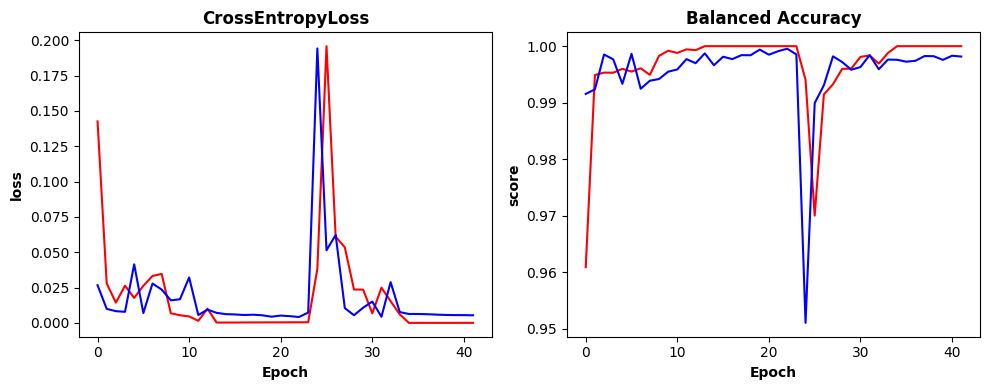

In [40]:
metric_and_loss_plot(RESULTS)

# **5. Final Predictions**

In [41]:
def predictions(test_dataloader:torch.utils.data.DataLoader):
    
    checkpoint = torch.load("best_model.pth")
    
    loaded_model = vit_b_16()
    
    loaded_model.heads = nn.Sequential(OrderedDict([('head', nn.Linear(in_features = 768, 
                                                                       out_features = output_shape))]))
    
    loaded_model.load_state_dict(checkpoint)
    
    loaded_model.to(device = DEVICE)
    
    loaded_model.eval()
    
    y_pred_test = []
    
    with torch.inference_mode():
        
        for X,_ in tqdm(test_dataloader):
            X = X.to(device = DEVICE, dtype = torch.float32)
            y_pred_logit = loaded_model(X)
            y_pred_prob = y_pred_logit.softmax(dim = 1)
            y_pred_class = y_pred_prob.argmax(dim = 1)
            y_pred_test.append(y_pred_class.detach().cpu())
            
    y_pred_test = torch.cat(y_pred_test)
    
    return y_pred_test
            

In [46]:
# We create our Dataset and DataLoader.
test_dataset = CustomImageDataset(data_testing, label2id, image_transforms)

test_dataloader = DataLoader(dataset = test_dataset, batch_size = BATCH_SIZE, 
                             shuffle = False, num_workers = NUM_WORKERS)

In [47]:
# We make the predictions.
y_pred_test = predictions(test_dataloader)

  0%|          | 0/40 [00:00<?, ?it/s]

- **Balanced Accuracy**

In [48]:
test_accuracy = balanced_accuracy_score(data_testing['Label'].map(label2id), y_pred_test.numpy())

print(f"Balanced Accuracy Test = {test_accuracy:.4f}")

Balanced Accuracy Test = 0.9921


- **Confusion Matrix**

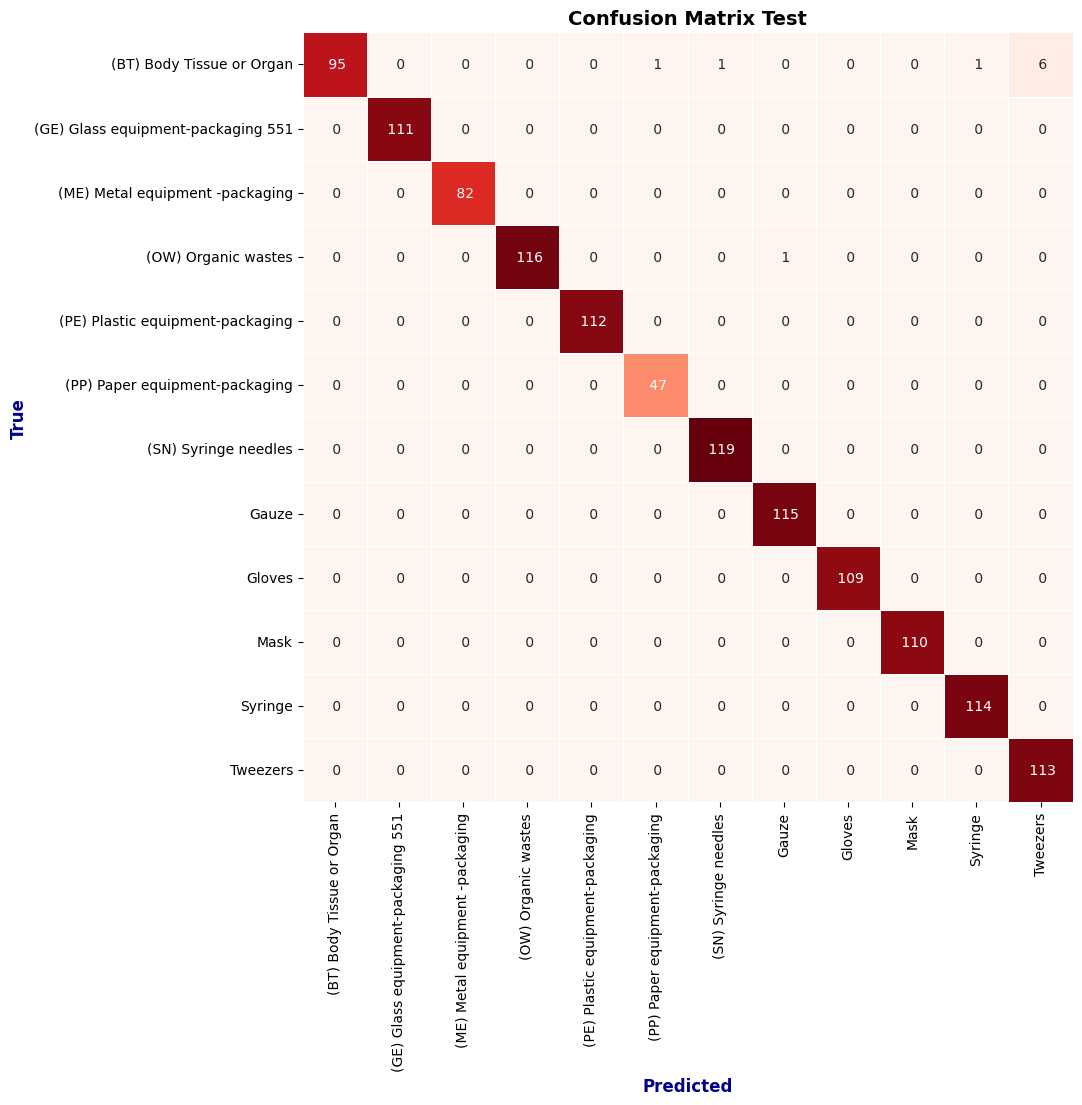

In [49]:
cf_mx_test = confusion_matrix(data_testing['Label'].map(label2id), y_pred_test.numpy())

fig,ax = plt.subplots(figsize = (10,10))
sns.heatmap(cf_mx_test, cmap = 'Reds', fmt = ' ', annot = True, cbar = False, square = True, linewidths = 0.4,
            xticklabels = CLASSES, yticklabels = CLASSES, ax = ax)
ax.set_ylabel("True", color = "darkblue", fontsize = 12, fontweight = "bold")
ax.set_xlabel("Predicted", color = "darkblue", fontsize = 12, fontweight = "bold")
ax.set_title("Confusion Matrix Test", fontsize = 14, fontweight = "bold", color = "black")

fig.show()